In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


In [ ]:
data = pd.read_csv(r"/content/customer_churn_dataset.csv")
data.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


# 1.Data overview

In [ ]:
#overview
data.shape

(505207, 12)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 505207 entries, 0 to 505206
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         505206 non-null  float64
 1   Age                505206 non-null  float64
 2   Gender             505206 non-null  object 
 3   Tenure             505206 non-null  float64
 4   Usage Frequency    505206 non-null  float64
 5   Support Calls      505206 non-null  float64
 6   Payment Delay      505206 non-null  float64
 7   Subscription Type  505206 non-null  object 
 8   Contract Length    505206 non-null  object 
 9   Total Spend        505206 non-null  float64
 10  Last Interaction   505206 non-null  float64
 11  Churn              505206 non-null  float64
dtypes: float64(9), object(3)
memory usage: 46.3+ MB


In [ ]:
#missing values
data.isnull().sum().sort_values(ascending=False)

,0
CustomerID,1
Age,1
Gender,1
Tenure,1
Usage Frequency,1
Support Calls,1
Payment Delay,1
Subscription Type,1
Contract Length,1
Total Spend,1


In [ ]:
data[data['CustomerID'].isnull()]

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
199295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
data = data[data['CustomerID'].notna()]
data.isnull().sum()

,0
CustomerID,0
Age,0
Gender,0
Tenure,0
Usage Frequency,0
Support Calls,0
Payment Delay,0
Subscription Type,0
Contract Length,0
Total Spend,0


In [ ]:
#transform col name into lower case and replace space with underscore
data.columns = data.columns.str.strip().str.lower().str.replace(' ','_', regex=False)
data.columns

Index(['customerid', 'age', 'gender', 'tenure', 'usage_frequency',
       'support_calls', 'payment_delay', 'subscription_type',
       'contract_length', 'total_spend', 'last_interaction', 'churn'],
      dtype='object')

In [ ]:
#duplicate
print(data['customerid'].nunique())
print(data['customerid'].count())

442211
505206


In [ ]:
test_dup = data.groupby('customerid')['churn'].count().reset_index()
test_dup[test_dup['churn']>1]

,customerid,churn
1,2.0,2
2,3.0,2
3,4.0,2
4,5.0,2
5,6.0,2
...,...,...
64368,64369.0,2
64369,64370.0,2
64371,64372.0,2
64372,64373.0,2


In [ ]:
data[data['customerid']==2.0]

,customerid,age,gender,tenure,usage_frequency,support_calls,payment_delay,subscription_type,contract_length,total_spend,last_interaction,churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
440834,2.0,41.0,Female,28.0,28.0,7.0,13.0,Standard,Monthly,584.0,20.0,0.0


In [ ]:
print(f'%duplicate: {len(test_dup[test_dup['churn']>1]['customerid'].unique())/len(test_dup['customerid'].unique())*100:2f}%')


%duplicate: 14.245462%


In [ ]:
list_dup_customer = test_dup[test_dup['churn']>1]['customerid'].unique()
data = data[~data['customerid'].isin(list_dup_customer)]
data.shape

(379216, 12)

In [ ]:
is_dup = data['customerid'].duplicated(keep=False)#trả về true cho tất cả dòng bị lặp
num_dup_ids = data[is_dup]['customerid'].nunique()
total_ids = data['customerid'].nunique()
print(f'%duplicate: {num_dup_ids/total_ids *100:.2f}%')

data = data[~is_dup]
data.shape

%duplicate: 0.00%


(379216, 12)

In [ ]:
id_counts = data['customerid'].value_counts()
num_dup_ids = (id_counts>1).sum()
total_ids = len(id_counts)
print(f'%duplicate: {num_dup_ids/total_ids *100:.2f}%')

data = data[data['customerid'].isin(id_counts[id_counts==1].index)]
print(data.shape)

%duplicate: 0.00%
(379216, 12)


In [ ]:
#unique value of category columns
object_cols = data.select_dtypes(include=['object']).columns
for col in object_cols:
  print(f"\nColumn: {col}")
  print(data[col].unique())


Column: gender
['Male' 'Female']

Column: subscription_type
['Premium' 'Basic' 'Standard']

Column: contract_length
['Monthly' 'Annual' 'Quarterly']


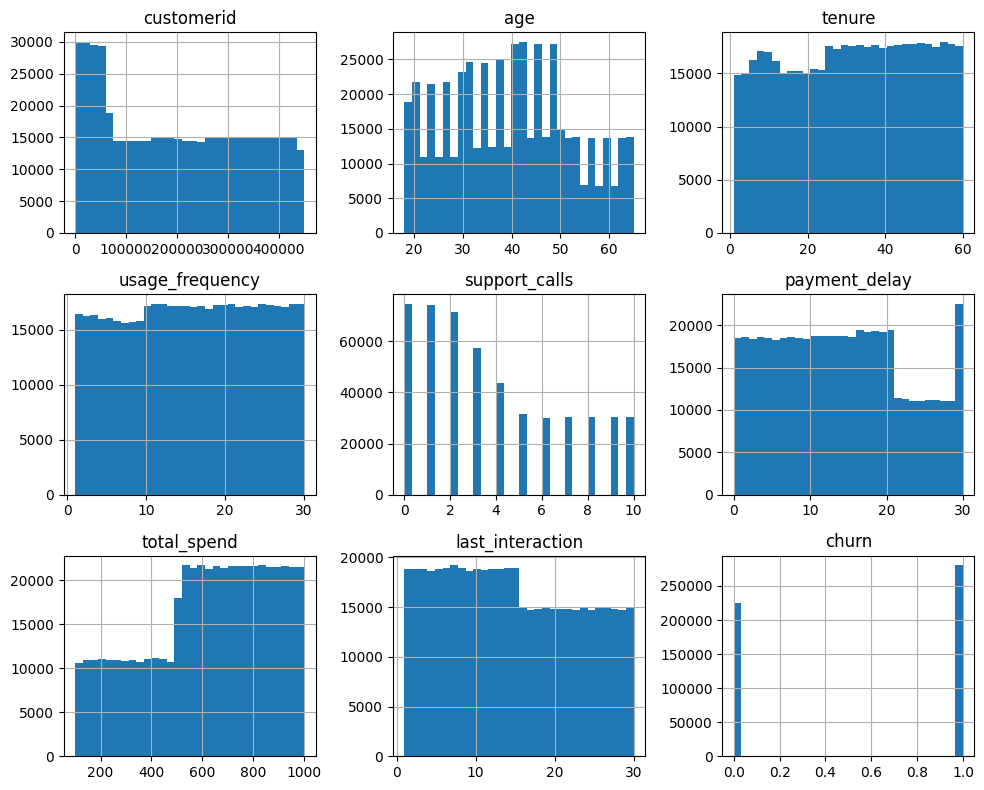

In [ ]:
#numeric columns
##distribution
data.select_dtypes(include ='number').hist(figsize=(10,8), bins=30, layout=(3,3));
plt.tight_layout()
plt.show()

In [ ]:
##outliers
summary = []
numeric_cols = data.select_dtypes(include='number').columns
for col in numeric_cols:
  q1 = data[col].quantile(0.25)
  q3 = data[col].quantile(0.75)
  iqr = q3 - q1
  lower_bound = q1 - 1.5 * iqr
  upper_bound = q3 + 1.5 * iqr
  n_outliers = ((data[col] < lower_bound) | (data[col] > upper_bound)).sum()

  summary.append({
      'Column': col,
      'Outliers': n_outliers,
      'Percentage': round(n_outliers / len(data) * 100, 2),
      'Has Outliers': n_outliers >0
  })
outlier_summary = pd.DataFrame(summary)
print(outlier_summary)

             Column  Outliers  Percentage  Has Outliers
0        customerid         0         0.0         False
1               age         0         0.0         False
2            tenure         0         0.0         False
3   usage_frequency         0         0.0         False
4     support_calls         0         0.0         False
5     payment_delay         0         0.0         False
6       total_spend         0         0.0         False
7  last_interaction         0         0.0         False
8             churn         0         0.0         False


# 2.EDA




In [ ]:
#churn rate

In [ ]:
##overall
churn_rate = data['churn'].value_counts(normalize = True)
print(f"Overall churn rate: {churn_rate[1]*100:.2f}%")


Overall churn rate: 49.91%


In [ ]:
##By subscription_type, contract_length
cat_cols = ['subscription_type', 'contract_length']
for col in cat_cols:
    summary = (data.groupby(col).agg(
            Total_Users=('churn', 'count'),
            Churn_Users=('churn', 'sum')
        ))

    summary['Churn_Rate'] = (summary['Churn_Users'] / summary['Total_Users'] * 100).round(2)

    print(f"\n===== {col} =====")
    print(summary)


===== subscription_type =====
                   Total_Users  Churn_Users  Churn_Rate
subscription_type                                      
Basic                   122655      63139.0       51.48
Premium                 128087      62873.0       49.09
Standard                128474      63270.0       49.25

===== contract_length =====
                 Total_Users  Churn_Users  Churn_Rate
contract_length                                      
Annual                156760      61732.0       39.38
Monthly                66240      66099.0       99.79
Quarterly             156216      61451.0       39.34


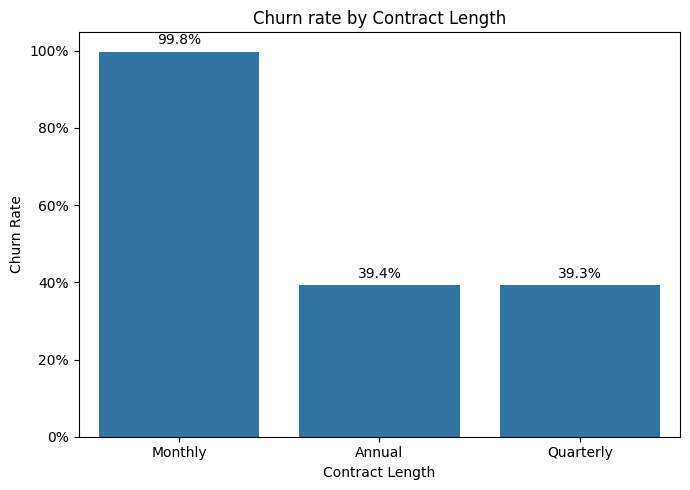

In [ ]:
churn_rate = (data.groupby('contract_length')['churn'].mean().reset_index())

plt.figure(figsize=(7,5))
ax = sns.barplot(data=data, x= 'contract_length', y ='churn', errorbar=None)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.bar_label(ax.containers[0], fmt=lambda x: f'{x:.1%}', padding=3)

plt.title("Churn rate by Contract Length")
plt.xlabel("Contract Length")
plt.ylabel("Churn Rate")

plt.tight_layout()
plt.show()


In [ ]:
##by payment_delay bucket
data['payment_delay'].describe()

,payment_delay
count,379216.000000
mean,12.633146
std,8.092188
min,0.000000
25%,6.000000
50%,12.000000
75%,18.000000
max,30.000000


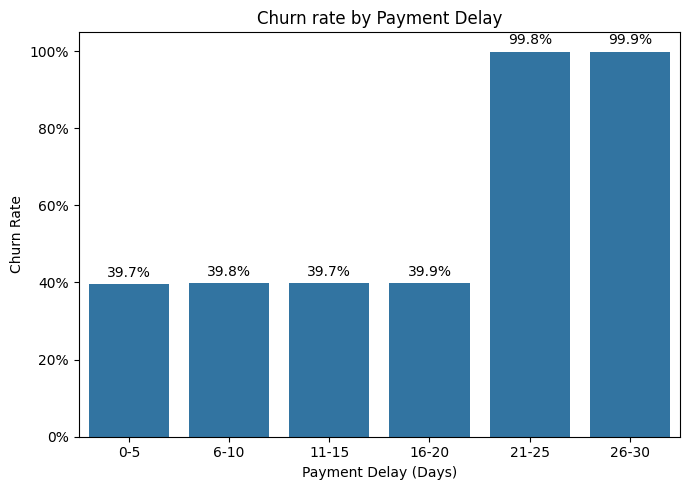

In [ ]:
bins = [0, 5, 10, 15, 20, 25, 30]
labels = ['0-5', '6-10', '11-15', '16-20', '21-25', '26-30']
data['delay_bucket'] = pd.cut(data['payment_delay'], bins = bins, labels = labels, include_lowest = True)

plt.figure(figsize = (7,5))
ax = sns.barplot(data = data, x = 'delay_bucket', y = 'churn', errorbar = None)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.bar_label(ax.containers[0], fmt = lambda x: f'{x:.1%}', padding = 3)

plt.title("Churn rate by Payment Delay")
plt.xlabel("Payment Delay (Days)")
plt.ylabel("Churn Rate")

plt.tight_layout()
plt.show()

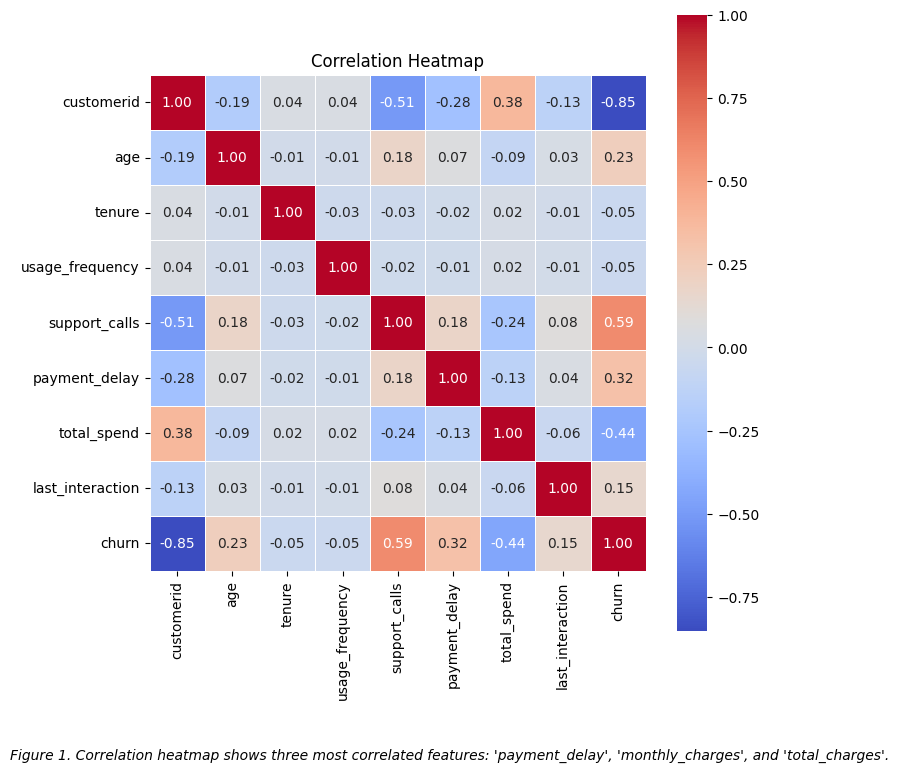

In [ ]:
#correlation matrix
corr_data = data.select_dtypes(include='number').corr()

plt.figure(figsize=(8, 8))
sns.heatmap(
    corr_data,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.figtext(
    0.5, -0.05,
    "Figure 1. Correlation heatmap shows three most correlated features: 'payment_delay', 'monthly_charges', and 'total_charges'.",
    ha='center',
    fontsize=10,
    style='italic'
)

plt.title('Correlation Heatmap')
plt.show()



*  support_calls & churn : moderate positive (0.59): frequently contact support ~ high churn
*  total_spend & churn: weak negative (-0.42): high spend ~ more loyal

*  payment_delay & churn: weak positive (0.32): frequently delay ~higher risk of churn






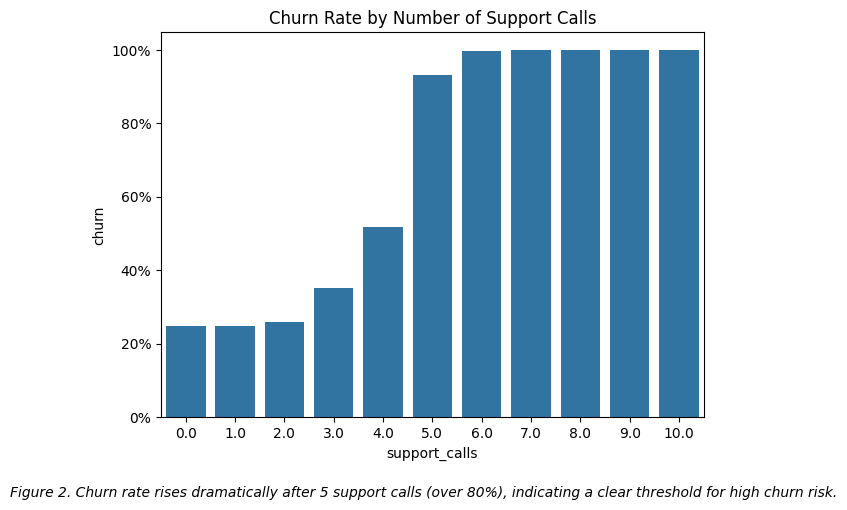

In [ ]:
##churn & support_calls
plt.figure(figsize=(7,5))
sns.barplot(data=data, x='support_calls', y='churn', errorbar=None)
plt.title('Churn Rate by Number of Support Calls')
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.figtext(
    0.5, -0.05,
    "Figure 2. Churn rate rises dramatically after 5 support calls (over 80%), indicating a clear threshold for high churn risk.",
    ha='center',
    fontsize=10,
    style='italic'
)

plt.show()


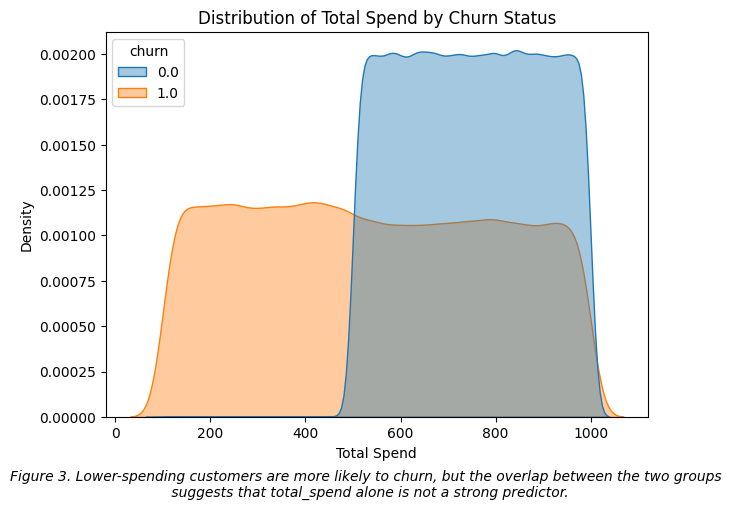

In [ ]:
##churn & total_spend
plt.figure(figsize=(7,5))

sns.kdeplot(
    data=data,
    x='total_spend',
    hue='churn',
    fill=True,
    common_norm=False,
    alpha=0.4
)

plt.title('Distribution of Total Spend by Churn Status')
plt.xlabel('Total Spend')
plt.ylabel('Density')

plt.figtext(
    0.5, -0.05,
    "Figure 3. Lower-spending customers are more likely to churn, but the overlap between the two groups \n suggests that total_spend alone is not a strong predictor.",
    ha='center',
    fontsize=10,
    style='italic'
)

plt.show()

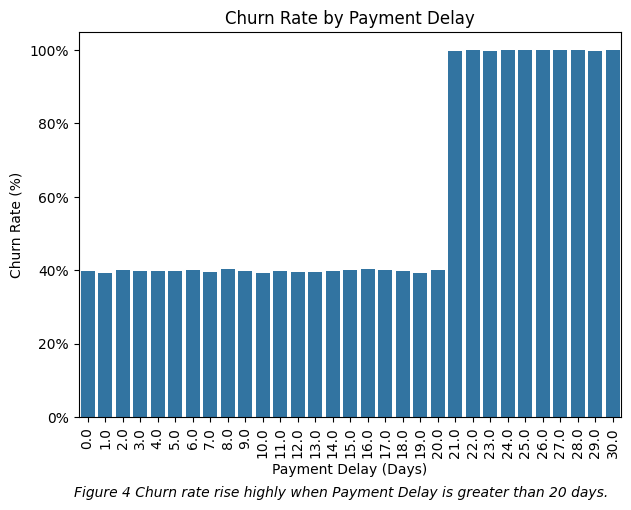

In [ ]:
#churn & payment_delay
plt.figure(figsize=(7,5))
sns.barplot(data=data, x='payment_delay', y='churn', errorbar=None)
plt.title('Churn Rate by Payment Delay')
plt.xlabel('Payment Delay (Days)')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=90)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.figtext(
    0.5, -0.05,
    "Figure 4 Churn rate rise highly when Payment Delay is greater than 20 days.",
    ha='center',
    fontsize=10,
    style='italic'
)

plt.show()

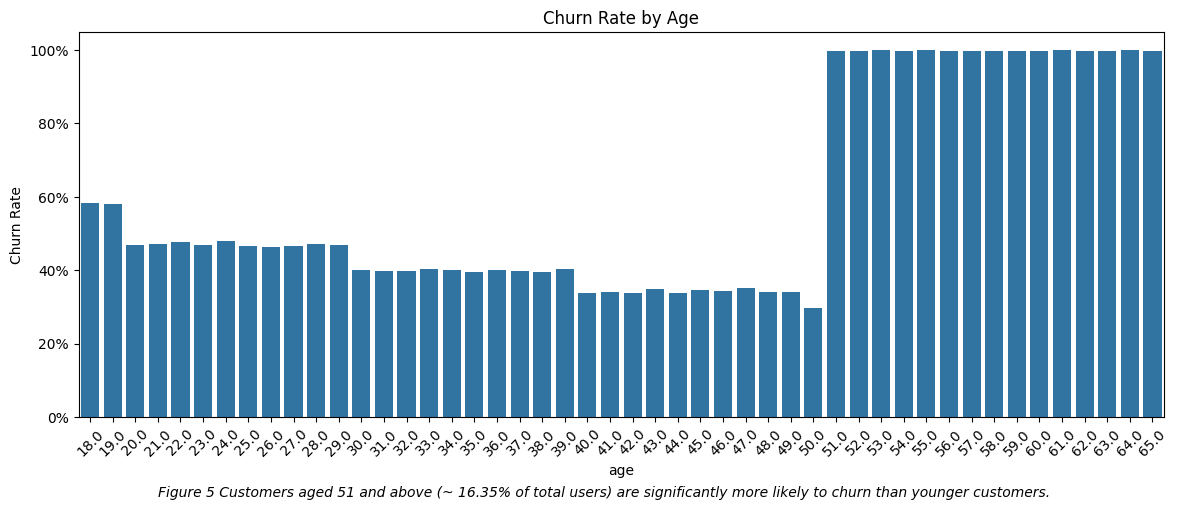

In [ ]:
#others: churn & age
churn_rate = (data.groupby('age')['churn'].mean().reset_index())

plt.figure(figsize=(14,5))
sns.barplot(data=churn_rate,x='age',y='churn')
plt.ylabel('Churn Rate')
plt.title('Churn Rate by Age')
plt.xticks(rotation=45)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.figtext(
    0.5, -0.05,
    "Figure 5 Customers aged 51 and above (~ 16.35% of total users) are significantly more likely to churn than younger customers.",
    ha='center',
    fontsize=10,
    style='italic'
)
plt.show()

In [ ]:
# Percentage of users aged 51+
pct_51_plus = (data['age'] >= 51).mean() * 100
print(f"Users aged 51+: {pct_51_plus:.2f}%")

Users aged 51+: 16.35%


# 3.Insight from EDA


1.   Support calls are strongly associated with churn. Customers with more than 5 support calls exhibit a dramatically higher churn rate, suggesting that frequent support interactions are a strong indicator of churn risk.
2.   Customers with payment delays of 21 days or more are almost universal churn rate, while those with shorter delays maintain a substantially lower churn rate.
3.   Contract length is closely related to customer retention. Customers on Monthly contracts (churn rate ~99,8%) exhibit a much higher churn rate than those on Annual or Quarterly contracts.
4.   Lower-spending (<500) customers are more likely to churn. Although customers with lower total_spend tend to churn more frequently, the overlap between the two distributions suggests that spending alone cannot fully explain churn behavior.
5.   Customers aged 51+ exhibit a noticeably higher churn rate than younger age groups, indicating that age may be associated with churn risk.







